**INSTALLATION  AND IMPORTING NECESSARY LIBRARY**


In [1]:
pip install chembl_webresource_client

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 KB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 KB 5.2 MB/s eta 0:00:00
  Attempting uninstall: itsdangerous
    Found existing installation: itsdangerous 1.1.0
    Uninstalling itsdangerous-1.1.0:
      Successfully uninstalled itsdangerous-1.1.0
  Attempting uninstall: attrs
    Found existing installation: attrs 22.2.0
    Uninstalling attrs-22.2.0:
      Successfully uninstalled attrs-22.2.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
flask 1.1.4 requires itsdangerous<2.0,>=0.24, but you have itsdangerous 2.1.2 which is incompatible.


In [ ]:
pip install pyopenssl

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 57 kB 4.5 MB/s 
     |████████████████████████████████| 4.0 MB 33.5 MB/s 


In [ ]:
pip install ndg-httpsclient

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
from chembl_webresource_client import *
import pandas as pd
import resource
import re
import tempfile
from abc import abstractmethod, ABCMeta
from chembl_webresource_client.utils import utils
from chembl_webresource_client.new_client import new_client
from chembl_webresource_client.elastic_client import ElasticClient

**DATA** **RETRIVAL** **FROM** **CHEMBL**

In [ ]:
target = new_client.target
target_query = target.search("BACE1")
targets = pd.DataFrame.from_dict(target_query)
targets

,cross_references,organism,pref_name,score,species_group_flag,target_chembl_id,target_components,target_type,tax_id
0,[],Cricetulus griseus,Beta-secretase 1,13.0,False,CHEMBL3297642,"[{'accession': 'G3IAK4', 'component_descriptio...",SINGLE PROTEIN,10029
1,"[{'xref_id': 'Beta-secretase_1', 'xref_name': ...",Homo sapiens,Beta-secretase 1,11.0,False,CHEMBL4822,"[{'accession': 'P56817', 'component_descriptio...",SINGLE PROTEIN,9606
2,"[{'xref_id': 'P56818', 'xref_name': None, 'xre...",Mus musculus,Beta-secretase 1,11.0,False,CHEMBL4593,"[{'accession': 'P56818', 'component_descriptio...",SINGLE PROTEIN,10090
3,[],Rattus norvegicus,Beta-secretase 1,11.0,False,CHEMBL3259473,"[{'accession': 'P56819', 'component_descriptio...",SINGLE PROTEIN,10116
4,[],Homo sapiens,Beta-secretase (BACE),6.0,False,CHEMBL2111390,"[{'accession': 'Q9Y5Z0', 'component_descriptio...",PROTEIN FAMILY,9606


In [ ]:
selected_target=targets.target_chembl_id[1]
selected_target

'CHEMBL4822'

In [ ]:
activity = new_client.activity
res = activity.filter(target_chembl_id=selected_target).filter(standard_type="IC50")
res 

[{'activity_comment': None, 'activity_id': 78857, 'activity_properties': [], 'assay_chembl_id': 'CHEMBL653511', 'assay_description': 'Inhibitory activity against Beta-secretase 1 was determined', 'assay_type': 'B', 'assay_variant_accession': None, 'assay_variant_mutation': None, 'bao_endpoint': 'BAO_0000190', 'bao_format': 'BAO_0000357', 'bao_label': 'single protein format', 'canonical_smiles': 'CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O)O)C(C)C)C(=O)N[C@@H](Cc1ccccc1)[C@@H](O)C(=O)N[C@@H](CC(=O)O)C(=O)N[C@@H](C)C(=O)N[C@@H](CCC(=O)O)C(=O)N[C@@H](Cc1ccccc1)C(=O)O', 'data_validity_comment': None, 'data_validity_description': None, 'document_chembl_id': 'CHEMBL1136466', 'document_journal': 'Bioorg. Med. Chem. Lett.', 'document_year': 2003, 'ligand_efficiency': {'bei': '6.39', 'le': '0.12', 'lle': '7.82', 'sei': '1.60'}, 'molecule_chembl_id': 'CHEMBL406146', 'molecule_pref_name': 'HGLUVALLEUPNSASPALAGLUPHEOH', 'parent_molecule_chembl_id': 'CHEMBL406146', 'pchembl_value': '6.38', 'pote

In [ ]:
df = pd.DataFrame.from_dict(res)
df

,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,bao_format,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,78857,[],CHEMBL653511,Inhibitory activity against Beta-secretase 1 w...,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,nM,UO_0000065,None,413.0
1,None,391560,[],CHEMBL653332,Compound was tested for its inhibitory activit...,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,0.002
2,None,391983,[],CHEMBL653512,Inhibition of human Beta-secretase 1,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,0.46
3,None,395858,[],CHEMBL653512,Inhibition of human Beta-secretase 1,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,9.0
4,None,395859,[],CHEMBL653512,Inhibition of human Beta-secretase 1,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,5.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10426,None,23311823,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL4844257,Inhibition of human recombinant BACE-1 express...,B,None,None,BAO_0000190,BAO_0000019,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,1.5
10427,None,23311824,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL4844257,Inhibition of human recombinant BACE-1 express...,B,None,None,BAO_0000190,BAO_0000019,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,4.18
10428,Not Determined,23311825,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL4844257,Inhibition of human recombinant BACE-1 express...,B,None,None,BAO_0000190,BAO_0000019,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,None,None,None,None
10429,Not Determined,23311826,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL4844257,Inhibition of human recombinant BACE-1 express...,B,None,None,BAO_0000190,BAO_0000019,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,None,None,None,None


In [ ]:
df.standard_type.unique()

In [ ]:
df.to_csv('bioactivity_data.csv', index=False)

In [ ]:
df2 = df[df.standard_value.notna()]
df2 = df2[df.canonical_smiles.notna()]
df2

In [ ]:
len(df2.canonical_smiles.unique())

7234

In [ ]:
df2_nr = df2.drop_duplicates(['canonical_smiles'])
df2_nr

,activity_comment,activity_id,activity_properties,assay_chembl_id,assay_description,assay_type,assay_variant_accession,assay_variant_mutation,bao_endpoint,bao_format,...,target_organism,target_pref_name,target_tax_id,text_value,toid,type,units,uo_units,upper_value,value
0,None,78857,[],CHEMBL653511,Inhibitory activity against Beta-secretase 1 w...,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,nM,UO_0000065,None,413.0
1,None,391560,[],CHEMBL653332,Compound was tested for its inhibitory activit...,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,0.002
2,None,391983,[],CHEMBL653512,Inhibition of human Beta-secretase 1,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,0.46
3,None,395858,[],CHEMBL653512,Inhibition of human Beta-secretase 1,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,9.0
4,None,395859,[],CHEMBL653512,Inhibition of human Beta-secretase 1,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,5.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10419,None,23300099,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL4841885,Inhibition of recombinant BACE-1 (unknown orig...,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,4.4
10420,None,23300100,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL4841885,Inhibition of recombinant BACE-1 (unknown orig...,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,9.2
10421,None,23300101,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL4841885,Inhibition of recombinant BACE-1 (unknown orig...,B,None,None,BAO_0000190,BAO_0000357,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,10.0
10424,None,23311821,"[{'comments': None, 'relation': '=', 'result_f...",CHEMBL4844257,Inhibition of human recombinant BACE-1 express...,B,None,None,BAO_0000190,BAO_0000019,...,Homo sapiens,Beta-secretase 1,9606,None,None,IC50,uM,UO_0000065,None,10.8


In [ ]:
selection = ['molecule_chembl_id','canonical_smiles','standard_value']
df3 = df2_nr[selection]
df3

,molecule_chembl_id,canonical_smiles,standard_value
0,CHEMBL406146,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,413.0
1,CHEMBL78946,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,2.0
2,CHEMBL324109,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,460.0
3,CHEMBL114147,CC(=O)NCC(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)...,9000.0
4,CHEMBL419949,CC(=O)N[C@@H](Cc1ccccc1)C(=O)N[C@@H](Cc1ccccc1...,5600.0
...,...,...,...
10419,CHEMBL4849016,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,4400.0
10420,CHEMBL4872824,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,9200.0
10421,CHEMBL4853052,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,10000.0
10424,CHEMBL4862716,CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNS(=O)(=O)c...,10800.0


In [ ]:
df3.to_csv('acetylcholinesterase_02_bioactivity_data_preprocessed.csv', index=False)

In [ ]:
df4 = pd.read_csv('bace1_02_bioactivity_data_preprocessed.csv')

In [ ]:
bioactivity_threshold = []
for i in df4.standard_value:
  if float(i) >= 10000:
    bioactivity_threshold.append("inactive")
  elif float(i) <= 1000:
    bioactivity_threshold.append("active")
  else:
    bioactivity_threshold.append("intermediate")

In [ ]:
mol_cid = []
for i in df2.molecule_chembl_id:
  mol_cid.append(i)

In [ ]:
bioactivity_class=pd.Series(bioactivity_threshold,name="class")
df5=pd.concat([df4,bioactivity_class],axis=1)
df5

,molecule_chembl_id,canonical_smiles,standard_value,class
0,CHEMBL406146,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,413.0,active
1,CHEMBL78946,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,2.0,active
2,CHEMBL324109,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,460.0,active
3,CHEMBL114147,CC(=O)NCC(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)...,9000.0,intermediate
4,CHEMBL419949,CC(=O)N[C@@H](Cc1ccccc1)C(=O)N[C@@H](Cc1ccccc1...,5600.0,intermediate
...,...,...,...,...
7229,CHEMBL4849016,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,4400.0,intermediate
7230,CHEMBL4872824,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,9200.0,intermediate
7231,CHEMBL4853052,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,10000.0,inactive
7232,CHEMBL4862716,CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNS(=O)(=O)c...,10800.0,inactive


In [ ]:
df5.to_csv('acetylcholinesterase_03_bioactivity_data_curated.csv', index=False)

**LIPINSKI** 

In [ ]:
! wget https://repo.anaconda.com/miniconda/Miniconda3-py37_4.8.2-Linux-x86_64.sh
! chmod +x Miniconda3-py37_4.8.2-Linux-x86_64.sh
! bash ./Miniconda3-py37_4.8.2-Linux-x86_64.sh -b -f -p /usr/local
! conda install -c rdkit rdkit -y
import sys
sys.path.append('/usr/local/lib/python3.7/site-packages/')

--2022-09-29 13:28:37--  https://repo.anaconda.com/miniconda/Miniconda3-py37_4.8.2-Linux-x86_64.sh
Resolving repo.anaconda.com (repo.anaconda.com)... 104.16.131.3, 104.16.130.3, 2606:4700::6810:8303, ...
Connecting to repo.anaconda.com (repo.anaconda.com)|104.16.131.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 85055499 (81M) [application/x-sh]
Saving to: ‘Miniconda3-py37_4.8.2-Linux-x86_64.sh’

Miniconda3-py37_4.8 100%[===================>]  81.12M   124MB/s    in 0.7s    

2022-09-29 13:28:38 (124 MB/s) - ‘Miniconda3-py37_4.8.2-Linux-x86_64.sh’ saved [85055499/85055499]

PREFIX=/usr/local
Unpacking payload ...
Solving environment: - \ done

## Package Plan ##

  environment location: /usr/local

  added / updated specs:
    - _libgcc_mutex==0.1=main
    - asn1crypto==1.3.0=py37_0
    - ca-certificates==2020.1.1=0
    - certifi==2019.11.28=py37_0
    - cffi==1.14.0=py37h2e261b9_0
    - chardet==3.0.4=py37_1003
    - conda-package-handling==1.6.0=py37h

In [ ]:
import numpy as np
import rdkit
from rdkit import Chem
from rdkit.Chem import Descriptors
import pandas as pd

In [ ]:
df = pd.read_csv('acetylcholinesterase_03_bioactivity_data_curated.csv')
df

,molecule_chembl_id,canonical_smiles,standard_value,class
0,CHEMBL406146,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,413.0,active
1,CHEMBL78946,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,2.0,active
2,CHEMBL324109,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,460.0,active
3,CHEMBL114147,CC(=O)NCC(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)...,9000.0,intermediate
4,CHEMBL419949,CC(=O)N[C@@H](Cc1ccccc1)C(=O)N[C@@H](Cc1ccccc1...,5600.0,intermediate
...,...,...,...,...
7229,CHEMBL4849016,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,4400.0,intermediate
7230,CHEMBL4872824,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,9200.0,intermediate
7231,CHEMBL4853052,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,10000.0,inactive
7232,CHEMBL4862716,CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNS(=O)(=O)c...,10800.0,inactive


In [ ]:
df_no_smiles = df.drop(columns='canonical_smiles')
df_no_smiles 

,molecule_chembl_id,standard_value,class
0,CHEMBL406146,413.0,active
1,CHEMBL78946,2.0,active
2,CHEMBL324109,460.0,active
3,CHEMBL114147,9000.0,intermediate
4,CHEMBL419949,5600.0,intermediate
...,...,...,...
7229,CHEMBL4849016,4400.0,intermediate
7230,CHEMBL4872824,9200.0,intermediate
7231,CHEMBL4853052,10000.0,inactive
7232,CHEMBL4862716,10800.0,inactive


In [ ]:
smiles = []

for i in df.canonical_smiles.tolist():
  cpd = str(i).split('.')
  cpd_longest = max(cpd, key = len)
  smiles.append(cpd_longest)

smiles = pd.Series(smiles, name = 'canonical_smiles')

In [ ]:
df_clean_smiles = pd.concat([df_no_smiles,smiles], axis=1)
df_clean_smiles

,molecule_chembl_id,standard_value,class,canonical_smiles
0,CHEMBL406146,413.0,active,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...
1,CHEMBL78946,2.0,active,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...
2,CHEMBL324109,460.0,active,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...
3,CHEMBL114147,9000.0,intermediate,CC(=O)NCC(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)...
4,CHEMBL419949,5600.0,intermediate,CC(=O)N[C@@H](Cc1ccccc1)C(=O)N[C@@H](Cc1ccccc1...
...,...,...,...,...
7229,CHEMBL4849016,4400.0,intermediate,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...
7230,CHEMBL4872824,9200.0,intermediate,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...
7231,CHEMBL4853052,10000.0,inactive,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...
7232,CHEMBL4862716,10800.0,inactive,CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNS(=O)(=O)c...


In [ ]:
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski
def lipinski(smiles, verbose=False):

    moldata= []
    for elem in smiles:
        mol=Chem.MolFromSmiles(elem) 
        moldata.append(mol)
       
    baseData= np.arange(1,1)
    i=0  
    for mol in moldata:        
       
        desc_MolWt = Descriptors.MolWt(mol)
        desc_MolLogP = Descriptors.MolLogP(mol)
        desc_NumHDonors = Lipinski.NumHDonors(mol)
        desc_NumHAcceptors = Lipinski.NumHAcceptors(mol)
           
        row = np.array([desc_MolWt,
                        desc_MolLogP,
                        desc_NumHDonors,
                        desc_NumHAcceptors])   
    
        if(i==0):
            baseData=row
        else:
            baseData=np.vstack([baseData, row])
        i=i+1      
    
    columnNames=["MW","LogP","NumHDonors","NumHAcceptors"]   
    descriptors = pd.DataFrame(data=baseData,columns=columnNames)
    
    return descriptors

In [ ]:
df_lipinski = lipinski(df_clean_smiles.canonical_smiles)
df_lipinski

,MW,LogP,NumHDonors,NumHAcceptors
0,999.085,-1.4355,13.0,13.0
1,893.005,-1.7361,12.0,12.0
2,751.988,2.3535,8.0,9.0
3,737.895,1.9626,8.0,8.0
4,828.020,3.5739,8.0,8.0
...,...,...,...,...
7229,623.861,2.3125,7.0,8.0
7230,637.888,2.7026,7.0,8.0
7231,651.915,3.0927,7.0,8.0
7232,556.176,6.7284,3.0,5.0


In [ ]:
df_lipinski

,MW,LogP,NumHDonors,NumHAcceptors
0,999.085,-1.4355,13.0,13.0
1,893.005,-1.7361,12.0,12.0
2,751.988,2.3535,8.0,9.0
3,737.895,1.9626,8.0,8.0
4,828.020,3.5739,8.0,8.0
...,...,...,...,...
7229,623.861,2.3125,7.0,8.0
7230,637.888,2.7026,7.0,8.0
7231,651.915,3.0927,7.0,8.0
7232,556.176,6.7284,3.0,5.0


In [ ]:
df

,molecule_chembl_id,canonical_smiles,standard_value,class
0,CHEMBL406146,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,413.0,active
1,CHEMBL78946,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,2.0,active
2,CHEMBL324109,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,460.0,active
3,CHEMBL114147,CC(=O)NCC(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)...,9000.0,intermediate
4,CHEMBL419949,CC(=O)N[C@@H](Cc1ccccc1)C(=O)N[C@@H](Cc1ccccc1...,5600.0,intermediate
...,...,...,...,...
7229,CHEMBL4849016,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,4400.0,intermediate
7230,CHEMBL4872824,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,9200.0,intermediate
7231,CHEMBL4853052,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,10000.0,inactive
7232,CHEMBL4862716,CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNS(=O)(=O)c...,10800.0,inactive


In [ ]:
df_combined = pd.concat([df,df_lipinski], axis=1)
df_combined

,molecule_chembl_id,canonical_smiles,standard_value,class,MW,LogP,NumHDonors,NumHAcceptors
0,CHEMBL406146,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,413.0,active,999.085,-1.4355,13.0,13.0
1,CHEMBL78946,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,2.0,active,893.005,-1.7361,12.0,12.0
2,CHEMBL324109,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,460.0,active,751.988,2.3535,8.0,9.0
3,CHEMBL114147,CC(=O)NCC(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)...,9000.0,intermediate,737.895,1.9626,8.0,8.0
4,CHEMBL419949,CC(=O)N[C@@H](Cc1ccccc1)C(=O)N[C@@H](Cc1ccccc1...,5600.0,intermediate,828.020,3.5739,8.0,8.0
...,...,...,...,...,...,...,...,...
7229,CHEMBL4849016,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,4400.0,intermediate,623.861,2.3125,7.0,8.0
7230,CHEMBL4872824,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,9200.0,intermediate,637.888,2.7026,7.0,8.0
7231,CHEMBL4853052,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,10000.0,inactive,651.915,3.0927,7.0,8.0
7232,CHEMBL4862716,CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNS(=O)(=O)c...,10800.0,inactive,556.176,6.7284,3.0,5.0


In [ ]:
import numpy as np

def pIC50(input):
    pIC50 = []

    for i in input['standard_value_norm']:
        molar = i*(10**-9) # Converts nM to M
        pIC50.append(-np.log10(molar))

    input['pIC50'] = pIC50
    x = input.drop('standard_value_norm', 1)
        
    return x

In [ ]:
df_combined.standard_value.describe()

count    7.234000e+03
mean     4.157136e+04
std      1.113669e+06
min      2.000000e-04
25%      2.920000e+01
50%      2.637500e+02
75%      3.300000e+03
max      8.600000e+07
Name: standard_value, dtype: float64

In [ ]:
-np.log10( (10**-9)* 100000000 )

1.0

In [ ]:
-np.log10( (10**-9)* 10000000000 )

-1.0

In [ ]:
def norm_value(input):
    norm = []

    for i in input['standard_value']:
        if i > 100000000:
          i = 100000000
        norm.append(i)

    input['standard_value_norm'] = norm
    x = input.drop('standard_value', 1)
        
    return x

In [ ]:
df_norm = norm_value(df_combined)
df_norm

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:10: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  # Remove the CWD from sys.path while we load stuff.


,molecule_chembl_id,canonical_smiles,class,MW,LogP,NumHDonors,NumHAcceptors,standard_value_norm
0,CHEMBL406146,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,active,999.085,-1.4355,13.0,13.0,413.0
1,CHEMBL78946,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,active,893.005,-1.7361,12.0,12.0,2.0
2,CHEMBL324109,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,active,751.988,2.3535,8.0,9.0,460.0
3,CHEMBL114147,CC(=O)NCC(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)...,intermediate,737.895,1.9626,8.0,8.0,9000.0
4,CHEMBL419949,CC(=O)N[C@@H](Cc1ccccc1)C(=O)N[C@@H](Cc1ccccc1...,intermediate,828.020,3.5739,8.0,8.0,5600.0
...,...,...,...,...,...,...,...,...
7229,CHEMBL4849016,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,intermediate,623.861,2.3125,7.0,8.0,4400.0
7230,CHEMBL4872824,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,intermediate,637.888,2.7026,7.0,8.0,9200.0
7231,CHEMBL4853052,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,inactive,651.915,3.0927,7.0,8.0,10000.0
7232,CHEMBL4862716,CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNS(=O)(=O)c...,inactive,556.176,6.7284,3.0,5.0,10800.0


In [ ]:
df_norm.standard_value_norm.describe()

count    7.234000e+03
mean     4.157136e+04
std      1.113669e+06
min      2.000000e-04
25%      2.920000e+01
50%      2.637500e+02
75%      3.300000e+03
max      8.600000e+07
Name: standard_value_norm, dtype: float64

In [ ]:
df_final = pIC50(df_norm)
df_final

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:11: FutureWarning: In a future version of pandas all arguments of DataFrame.drop except for the argument 'labels' will be keyword-only
  # This is added back by InteractiveShellApp.init_path()


,molecule_chembl_id,canonical_smiles,class,MW,LogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL406146,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,active,999.085,-1.4355,13.0,13.0,6.384050
1,CHEMBL78946,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,active,893.005,-1.7361,12.0,12.0,8.698970
2,CHEMBL324109,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,active,751.988,2.3535,8.0,9.0,6.337242
3,CHEMBL114147,CC(=O)NCC(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)...,intermediate,737.895,1.9626,8.0,8.0,5.045757
4,CHEMBL419949,CC(=O)N[C@@H](Cc1ccccc1)C(=O)N[C@@H](Cc1ccccc1...,intermediate,828.020,3.5739,8.0,8.0,5.251812
...,...,...,...,...,...,...,...,...
7229,CHEMBL4849016,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,intermediate,623.861,2.3125,7.0,8.0,5.356547
7230,CHEMBL4872824,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,intermediate,637.888,2.7026,7.0,8.0,5.036212
7231,CHEMBL4853052,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,inactive,651.915,3.0927,7.0,8.0,5.000000
7232,CHEMBL4862716,CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNS(=O)(=O)c...,inactive,556.176,6.7284,3.0,5.0,4.966576


In [ ]:
df_final.pIC50.describe()

count    7234.000000
mean        6.477377
std         1.391441
min         1.065502
25%         5.481486
50%         6.578808
75%         7.534617
max        12.698970
Name: pIC50, dtype: float64

In [ ]:
df_final.to_csv('acetylcholinesterase_04_bioactivity_data_3class_pIC50.csv')

In [ ]:
df_2class =df_final
df_2class

,Unnamed: 0,molecule_chembl_id,canonical_smiles,class,MW,LogP,NumHDonors,NumHAcceptors,pIC50
0,0,CHEMBL406146,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O...,active,999.085,-1.4355,13.0,13.0,6.384050
1,1,CHEMBL78946,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](N...,active,893.005,-1.7361,12.0,12.0,8.698970
2,2,CHEMBL324109,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H]...,active,751.988,2.3535,8.0,9.0,6.337242
3,3,CHEMBL114147,CC(=O)NCC(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)...,intermediate,737.895,1.9626,8.0,8.0,5.045757
4,4,CHEMBL419949,CC(=O)N[C@@H](Cc1ccccc1)C(=O)N[C@@H](Cc1ccccc1...,intermediate,828.020,3.5739,8.0,8.0,5.251812
...,...,...,...,...,...,...,...,...,...
7229,7229,CHEMBL4849016,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,intermediate,623.861,2.3125,7.0,8.0,5.356547
7230,7230,CHEMBL4872824,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,intermediate,637.888,2.7026,7.0,8.0,5.036212
7231,7231,CHEMBL4853052,CC[C@H](C)[C@H](NC(=O)[C@@H](N)CCC(=O)O)C(=O)N...,inactive,651.915,3.0927,7.0,8.0,5.000000
7232,7232,CHEMBL4862716,CC1=CC2Cc3nc4cc(Cl)ccc4c(NCCCCCCCCCNS(=O)(=O)c...,inactive,556.176,6.7284,3.0,5.0,4.966576


In [ ]:
df_2class.to_csv('acetylcholinesterase_05_bioactivity_data_2class_pIC50.csv')

In [ ]:
import seaborn as sns
sns.set(style='ticks')
import matplotlib.pyplot as plt

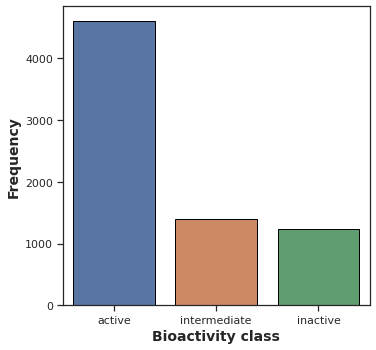

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.countplot(x='class', data=df_2class, edgecolor='black')

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('Frequency', fontsize=14, fontweight='bold')

plt.savefig('plot_bioactivity_class.pdf')

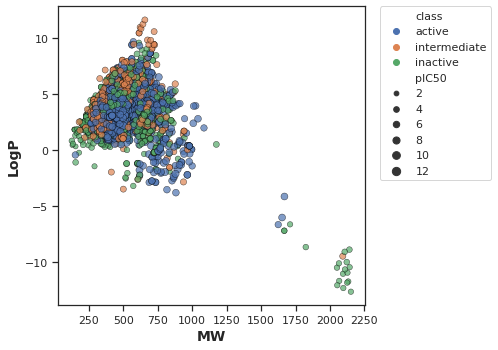

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.scatterplot(x='MW', y='LogP', data=df_2class, hue='class', size='pIC50', edgecolor='black', alpha=0.7)

plt.xlabel('MW', fontsize=14, fontweight='bold')
plt.ylabel('LogP', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0)
plt.savefig('plot_MW_vs_LogP.pdf')

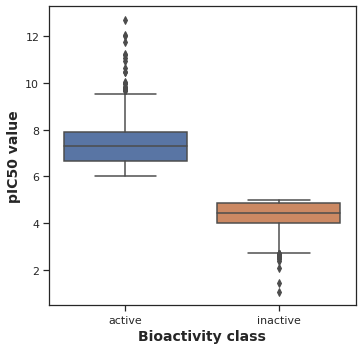

In [ ]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'class', y = 'pIC50', data = df_2class)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('pIC50 value', fontsize=14, fontweight='bold')

plt.savefig('plot_ic50.pdf')